# TP: Image encryption decryption using RSA 

## TASK 01: Hybrid Public-Key Encryption:

#### First we define some help function 

##### The first 3 function are to convert between binary and decimal systems 

###### function that convert a decimal number to binary with fixed number of bits 

In [35]:
def decimal_to_binary(n, bits ):
    binary = bin(n)[2:] # converts n into a binary then removes the first two characters which Python adds automatically.
    if len(binary) > bits:   # if length already greater we can not compress it 
        raise ValueError("Number cannot fit in the specified bit size")
        
    return binary.zfill(bits)      # we add 0 to reach the size we want 
   

###### function to convert a decimal number to a binary_list 

In [36]:
def int_to_bin(n):
    bin_rep=[]                                         
    # for calculating the number of bits required to represent a decimal number in binary
    number_of_bits = n.bit_length()
    for i in range(1,number_of_bits + 1):        # The sucsisive division of n over the powers of 2 
            if(n/(2**(number_of_bits-i)) <1):           #Cheking each time if the division of n over the power of two gives a number smaller than 1
                bin_rep.append(0)                       # we append 0
            else:                                        #if it is bigger we append 1  
                bin_rep.append(1)
                n = n - 2**(number_of_bits-i)            #if we append 1, we update n by subtracting that value
   
    return bin_rep

###### function to convert a binary number to decimal

In [37]:
def right_to_left_binary(n):               # n is a binary number
    b = [int(x) for x in str(n)][::-1]     # b is a list of bits of n 
    q = 0
    p = 1
    for i in range(0,len(b)):
        if b[i] == 1 :
            q = q + p
        p = p + p
        
    return q


##### Now, we define the power modulus function

In [38]:
def power(base, expo, m):
    result = 1
    # update base if it is greater than or equal to mod
    base = base % m  
    binary = int_to_bin(expo)    # return a list of the binary bits
    n = len(binary)
    for i in range(n-1, -1, -1):  # from right to left
        if binary[i] == 1 :
            result = (result * base) % m
        base = (base*base) % m
        
    return result

##### Now , we define a function to test the primality on intgers

In [39]:
def is_prime_Miller_Rabin(p, k=150):
    if p == 2:
        return True
    if p < 2 or p % 2 == 0:
        return False

    # writing p-1 = 2^s * d with d odd
    d = p - 1
    s = 0                # counter for the power of 2
    while d % 2 == 0:    # to check d is odd if not continue
        d //= 2
        s += 1

    # perform k rounds
    for _ in range(k):
        a = random.randint(2, p - 2)   # we choose a random base a
        x = pow(a, d, p)               

        if x == 1 or x == p - 1:
            continue                   # it means it is probably prime so we do not complete the next steps we directly redo the process for k+1

        for _ in range(s - 1):         # probably prime so we beak directely and we try for k+1
            x = pow(x, 2, p)
            if x == p - 1:
                break
        else:
            return False   # not prime 

    return True  # if it passes the loop then it is probably prime


##### Function for the GCD

In [40]:
def greatest_commen_divisor(a,b):
   
    u0 ,u1 = 1 , 0 
    v0 ,v1 = 0 , 1
    r0 , r1 = a ,b 
    while r1 > 0:         # we continue until the reminder is 0
        q = r0 // r1      # the quotient
        r = r0 % r1       # the reminder
        u = u0 - q * u1
        v = v0 - q * v1
        # updating the values
        r0 = r1 ; r1 = r
        u0 = u1 ; u1 = u
        v0 = v1 ; v1 = v
    return r0 , u0 , v0     # r0 = gcd(a,b)

##### A function for RSA key generation

In [41]:
import random

def RSA_keys ():
    # generating p , q
    p=0
    while not is_prime_Miller_Rabin(p):            
        p = random.randint(2**1023,2**1024)     # choosing large prime numbers p and q

    q=0
    while not is_prime_Miller_Rabin(q) or p==q :
        q = random.randint(2**1023,2**1024)
    
    # calculating n
    n=p*q
    # calculating phi(n))
    phi=(p-1)*(q-1)     

    # finding the public exponent e 
    best_e = [65537, 257, 17, 5, 3]   # we first try the usual best value of e used
    e = 0  # to verify if e get a value or still we did not find one 

    for i in best_e:
        gcd,_,_= greatest_commen_divisor(i, phi)
        if i < phi and gcd == 1:      # check if it satisfies the conditions
           e = i

    if e == 0 :      # if non of the best values worked we do this 
        k_start = 5  # because the first 5 are the best values we did them already
        k_end = 10
        while e == 0:
            #  generate Fermat numbers F_i = 2^(2^i) + 1 and putting them in a list 
            fermat_list = [2**(2**i) + 1 for i in range(k_start,k_end)]  

            # we reorder them for randomness
            random.shuffle(fermat_list)

            # we check if there exist a value that satisfies the conditions
            for i in fermat_list:
                gcd,_,_ = greatest_commen_divisor(i, phi)
                if i < phi and gcd == 1:      
                   e = i
            if e == 0 :      # if all does't satisfy we try the next 5 Fermat numbers 
                k_start = k_end
                k_end =+5

    # finding the private exponent d 
    gcd , d_first , l = greatest_commen_divisor(e, phi)     # solving the equation e.d - k.phi = 1 using the EEA
    d = d_first % phi                                       # calculating d modulo phi

    return n , e , d , p ,q

##### This is a function for RSA encryption

In [42]:
def RSA_encryption (blocks_int , e , n):
    
    encrypted = [power(num, e, n) for num in blocks_int]
    
    return encrypted

##### This is a function for RSA decryption

In [43]:
def RSA_decryption (encrypted, p , q , n , d):
    # decrypting using CRT
    gcd, q_inv1, _ = greatest_commen_divisor(q, p)  # calculation of q_inv
    q_inv = q_inv1  % p
    decrypted = []               # list of the decrypted result 
    
    for c in encrypted:          # decrypt each ciphertext (block)
         m_p = power(c, d, p)
         m_q = power(c, d, q)
        
         h = (q_inv * ((m_p - m_q) %p)) % p
         m = (m_q + q * h) % n
        
         decrypted.append(m) 
    return decrypted

### function that displays the encrypted image 

In [44]:
import numpy as np
from PIL import Image
import math

def encrypted_image(encrypted_2, letter): # if letter=R then RSA or RSA+Padding else AES
    
    if letter== 'R': 
        # convert the encrypted list to binary to be able to divide each block to pixels bit
        binary_encrypted_2=[]
        for cipher_2 in encrypted_2:
            byte_length_2 = (cipher_2.bit_length() + 7) // 8     # computes the minimum number of bytes needed to represent each ciphertext
            binary_encrypted_2.append(decimal_to_binary( cipher_2 , byte_length_2*8 ) )

        # going back to binary pixel each pixel alone  
        all_bits_2 = ''.join(binary_encrypted_2)
        pixel_bit_2 = [
               all_bits_2[i:i+8]
               for i in range(0, len(all_bits_2), 8)
               ]

        # convert the pixel bits to decimal 
        pixels_2 = [right_to_left_binary(b) for b in pixel_bit_2]
        
    else:    # the case of AES
        pixels_2 = encrypted_2

        
    # display the image 
    arr_2 = np.array(list(pixels_2), dtype=np.uint8)
    # Compute image dimensions for this array 
    length_2 = len(arr_2)

    width_2 = math.ceil(math.sqrt(length_2))  # we try to make the image size square 
    height_2 = math.ceil(length_2 / width_2)

    # since width*height may not = len(arr) exactly so we may need Padding in this case 
    padded_size_2 = width_2 * height_2

    if padded_size_2 > length_2:

        padding_2 = np.zeros(
            padded_size_2 - length_2,
            dtype=np.uint8
        )
        arr_2 = np.concatenate((arr_2, padding_2))
        
    arr_2 = arr_2.reshape((height_2, width_2))
    img_2 = Image.fromarray(arr_2)
    return img_2

#### Now we move to the step of image processing

0 = grayscale | 1 = colored :  0


 the original image before treating it with RSA 


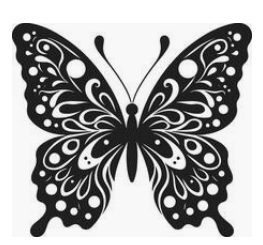

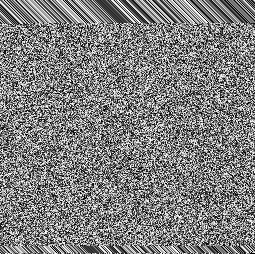

Decrypted image


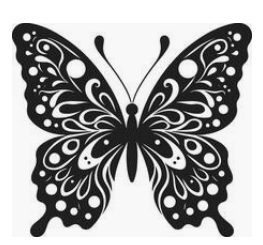

Execution Time is: 17.13881540298462 seconds


In [51]:
import time
start_time = time.time()
from IPython.display import display

# Open image
img = Image.open("Black_and_white_butterfly.png")
if int(input("0 = grayscale | 1 = colored : ")) == 0:
    img = img.convert("L")    # we make the image uncolored
    
print (" the original image before treating it with RSA ")
display(img)

# finding the  height and width of the image
width , height = img.size 

# Convert image to numpy array
arr = np.array(img)

# Convert image to a 1D sequence of pixels
sequence = arr.flatten()
   
# Convert to Python list if needed
sequence_list = sequence.tolist()

# pixel list in binary 
binary_pixels = [format(i , '08b') for i in sequence_list]

# generate the RSA keys 
n , e , d , p ,q = RSA_keys ()

# finding the block size = number of pixel taken 
block_size = (math.floor(math.log2(n)))// 8

# constructing the blocks in binary 
blocks = [
    ''.join(binary_pixels[i:i + block_size])             # concatenation of pixels bits 
    for i in range(0, len(binary_pixels), block_size)
]

# converting each block number to decimal to encrypt it 
blocks_int= [ right_to_left_binary (i) for i in blocks ]
last_block_size = len(str(blocks[len(blocks)-1]))    

# calling the RSA function to encrypt the pixels blocks
encrypted = RSA_encryption (blocks_int , e , n)

''' CREATE A VISUAL ENCRYPTED IMAGE '''
encrypted_img = encrypted_image(encrypted, 'R' )
display (encrypted_img)

# calling the RSA function to decrypt the ciphertexts 
decrypted = RSA_decryption (encrypted, p , q , n ,d )

''' recover the image pixel sequence after decryption '''

# convert the decrypted list to binary to be able to divide each block to pixels bit
binary_decrypted=[]
for i in range (0,len(decrypted)-1):
    binary_decrypted.append(decimal_to_binary( decrypted[i] , block_size*8 ))
binary_decrypted.append(decimal_to_binary ( decrypted[len(decrypted)-1] , last_block_size))

# going back to binary pixel each pixel alone  
all_bits = ''.join(binary_decrypted)
recovered_pixel_bit = [
       all_bits[i:i+8]
       for i in range(0, len(all_bits), 8)
       ]

# convert the pixel bits to decimal 
recovered_pixel = [right_to_left_binary(b) for b in recovered_pixel_bit]

''' display the image each mode alone '''

# for colored image 
if img.mode == 'RGB':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 3))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGB')
    
if img.mode == 'RGBA':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 4))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGBA')


# for uncolored image 
if img.mode == 'L':
    arr = np.array(recovered_pixel)
    arr = arr.reshape((height, width))
    img_rec = Image.fromarray(arr.astype('uint8'), mode='L')

print("Decrypted image")
display(img_rec)
end_time = time.time()
print("Execution Time is:", end_time - start_time, "seconds")



### TASK 02: Improving RSA Security:

#### OAEP PADDING IMPLEMENTATION

###### THE Mask Generation Function

In [46]:
import hashlib
import math
def mgf(seed,mask_len):
    # seed input to generate , mask_len : the size of the output 
    # we suppose that we use SHA 256 
    hash_func = hashlib.sha256
    hLen = 32
    number_of_blocks = math.ceil(mask_len / hLen )
    T = b''
    for counter in range(number_of_blocks):
        c = counter.to_bytes(4, byteorder='big')
        T+=hash_func(seed+c).digest()
    return T[:mask_len]

###### The xor between two bytes

In [47]:
def xor_bytes(a, b):
    return bytes(i ^ j for i, j in zip(a, b))

##### Encoding PART

In [48]:
import hashlib
import os

def oaep_encode(message, k, label=b''): # k represent the length of n in bytes | LABEL string -encoding parameter, we take it as empty string-
    #----------DATA BLOCK PREPARATION-----------------------------------
    mLen = len(message)
    hash_func = hashlib.sha256
    hLen = 32  # we work with sha256
    lHash = hash_func(label).digest()
    #----padding string------(ps)
    length_of_ps = k - mLen - 2*hLen - 2
    ps = b'\x00' * length_of_ps
    DB = lHash + ps + b'\x01' + message
    #-----Randomization --------
    #random seed of length 32
    seed = os.urandom(hLen)
    #first masking 
    dbMask = mgf(seed,len(DB))
    maskedDB = xor_bytes(DB, dbMask)
  
    #second masking
    seedMask = mgf(maskedDB, hLen)
    maskedSeed = xor_bytes(seed, seedMask)
    EM = b'\x00' + maskedSeed + maskedDB

    return EM
    
    

##### Decodeing part

In [49]:
def oaep_decode(EM, k, label=b''):
    hash_func = hashlib.sha256
    hLen = 32
    # devide the EM 
    Y = EM[0]
    maskedSeed = EM[1:hLen+1]
    maskedDB = EM[hLen+1:]
    # recover seedMask
    seedMask = mgf(maskedDB, hLen)
    # recover seed
    seed = xor_bytes(maskedSeed, seedMask)
    # recover dbMask
    dbMask = mgf(seed, len(maskedDB))
    # recover DB
    DB = xor_bytes(maskedDB, dbMask)
    # verify lHash
    lHash = hash_func(label).digest()
    lHash2 = DB[:hLen]
    if lHash != lHash2:
        raise ValueError("decryption error")
    # find separator 0x01
    rest = DB[hLen:]
    idx = rest.find(b'\x01')
    if idx == -1:
        raise ValueError("decryption error")
    # extract message
    message = rest[idx+1:]
    return message

### Now , We Move To The  Image Encryption - Decryption Using RSA+Padding

0 = grayscale | 1 = colored :  0


 the original image before treating it with RSA+Padding is: 


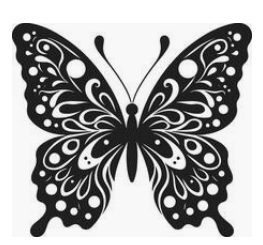

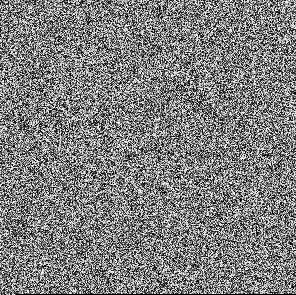

decrypted image


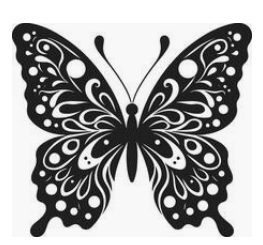

Execution Time: 30.314766883850098 seconds


In [53]:
start_time = time.time()
# Open image
img = Image.open("Black_and_white_butterfly.png")

if int(input("0 = grayscale | 1 = colored : ")) == 0:
    img = img.convert("L")    # we make the image uncolored
    
print (" the original image before treating it with RSA+Padding is: ")
display(img)

# finding the  height and width of the image
width , height = img.size 

# Convert image to numpy array
arr = np.array(img)

# Convert image to a 1D sequence of pixels
sequence = arr.flatten()
   
# Convert to Python list if needed
sequence_list = sequence.tolist()

# pixel list in binary 
binary_pixels = [format(i , '08b') for i in sequence_list]

n_1 , e_1 , d_1 , p_1 ,q_1 = RSA_keys ()

# finding the block size = number of pixel taken 
hLen = 32
k = (n.bit_length() + 7) // 8

# we calculate the block size as before then we substruct the length of what we will add it in the OEAP padding
# hLen for seed , hlen for hashing the label ,1 byte for separator and 1 for the leading 0x00
block_size_1 = ( k - 2*hLen - 2)

# constructing the blocks in binary 
blocks = [
    ''.join(binary_pixels[i:i + block_size_1])             # concatenation of pixels bits 
    for i in range(0, len(binary_pixels), block_size_1)
]

# converting each block number to decimal to encrypt it 
blocks_int= [ right_to_left_binary (i) for i in blocks ]
last_block_size_1 = len(str(blocks[len(blocks)-1]))

#convert the block of integers to a block of bytes-OEAP works with bytes 
blocks_bytes = [
    block.to_bytes((block.bit_length() + 7)//8, 'big')
    for block in blocks_int
]
blocks_int_oeap = [oaep_encode(block, k, label=b'') for block in blocks_bytes]

# calling the RSA function to encrypt the pixels blocks 
#we must convert the blocks from bytes to integers 
encrypted_1 = [
    power(int.from_bytes(block, 'big'), e_1, n_1)
    for block in blocks_int_oeap
]

''' CREATE A VISUAL ENCRYPTED IMAGE '''
encrypted_img_padding = encrypted_image(encrypted_1 , 'R')
display(encrypted_img_padding)

# calling the RSA function to decrypt the ciphertexts 
decrypted_1 = RSA_decryption (encrypted_1, p_1 , q_1 , n_1 , d_1 )

#convert the decrypted block into bytes for use it in oaep_decode
decrypted_bytes = [
    block.to_bytes(k, 'big')
    for block in decrypted_1
]
decrypted_decoded =[ oaep_decode(decrypted_block, k, label=b'') for decrypted_block in decrypted_bytes]
decrypted_decoded_int= [
    int.from_bytes(block, 'big')
    for block in decrypted_decoded
]

''' recover the image pixel sequence after decryption '''

# convert the decrypted list to binary to be able to divide each block to pixels bit
binary_decrypted=[]
for i in range (0,len(decrypted_decoded)-1):
    binary_decrypted.append(decimal_to_binary(
    int.from_bytes(decrypted_decoded[i], 'big'),
    block_size_1 * 8
))
binary_decrypted.append(
    decimal_to_binary(
        int.from_bytes(decrypted_decoded[-1], 'big'),
        last_block_size_1
    )
)

# going back to binary pixel each pixel alone  
all_bits = ''.join(binary_decrypted)
recovered_pixel_bit = [
       all_bits[i:i+8]
       for i in range(0, len(all_bits), 8)
       ]

# convert the pixel bits to decimal 
recovered_pixel = [right_to_left_binary(b) for b in recovered_pixel_bit]

''' display the image each mode alone '''

# for colored image 
if img.mode == 'RGB':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 3))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGB')
    
if img.mode == 'RGBA':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 4))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGBA')


# for uncolored image 
if img.mode == 'L':
    arr = np.array(recovered_pixel)
    arr = arr.reshape((height, width))
    img_rec = Image.fromarray(arr.astype('uint8'), mode='L')

print("decrypted image")
display(img_rec)
end_time = time.time()
print("Execution Time:", end_time - start_time, "seconds")


# TASK03 :  Hybrid Encryption with AES

In [17]:
!pip install pycryptodome

0 = grayscale | 1 = colored :  0


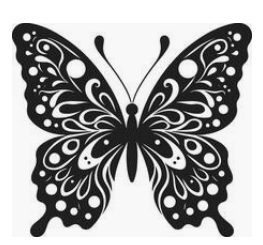

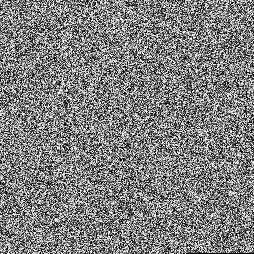

Decrypted Image


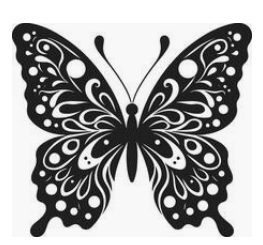

Execution Time: 7.956896066665649 seconds


In [54]:
import time, os, numpy as np
from PIL import Image
from IPython.display import display
from Crypto.Cipher import AES
from Crypto.Util.Padding import pad, unpad

start_time = time.time()

# open image
img = Image.open("Black_and_white_butterfly.png")

if int(input("0 = grayscale | 1 = colored : ")) == 0:
    img = img.convert("L")    # we make the image uncolored
display(img)

width, height = img.size
arr = np.array(img)

# image to bytes
image_bytes = arr.tobytes()

# AES encryption
aes_key = os.urandom(32)

cipher = AES.new(aes_key, AES.MODE_CBC)

ciphertext = cipher.encrypt(pad(image_bytes , AES.block_size))

iv = cipher.iv

''' display the encrypted image '''
encrypted_img_AES = encrypted_image(ciphertext , 'A')
display(encrypted_img_AES)

# RSA KEY EXCHANGE
# (using your RSA functions)
n_2, e_2, d_2, p_2, q_2 = RSA_keys()

# convert the AES key to integer
aes_int = int.from_bytes(aes_key, 'big')

# RSA encryption
encrypted_key = power(aes_int, e_2, n_2)

# RSA decryption
decrypted_key_int = power(encrypted_key, d_2, n_2)

# integer to bytes
recovered_key = decrypted_key_int.to_bytes(32, 'big')

# AES DECRYPTION
cipher_dec = AES.new(recovered_key , AES.MODE_CBC , iv=iv)

decrypted_bytes = unpad(cipher_dec.decrypt(ciphertext), AES.block_size)


# Rebuild image
recovered_arr = np.frombuffer(decrypted_bytes , dtype=np.uint8).reshape(arr.shape)
img_rec = Image.fromarray(recovered_arr.astype(np.uint8) , mode=img.mode)

print("Decrypted Image")
display(img_rec)

# execution time 
end_time = time.time()
print("Execution Time:", end_time - start_time, "seconds")


# Task 04: Standard Image Encryption Metrics

### Histogram Analysis Function

In [55]:
import matplotlib.pyplot as plt
from PIL import Image

def plot_histogram(img, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    # on the left we show the image 
    axes[0].imshow(img, cmap='gray')
    axes[0].set_title("Image")
    axes[0].axis('off')

    # on the right we show the histogram of the image
    axes[1].hist(np.array(img).ravel(), bins=256, range=[0,256], color='black')
    axes[1].set_title("Histogram")
    axes[1].set_xlabel("Pixel Value")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()


### Correlation Analysis Function

In [56]:
def correlation_coefficient(x, y):
    """Compute correlation coefficient between two arrays"""
    x = x.astype(np.float64)
    y = y.astype(np.float64)
    Ex  = np.mean(x)
    Ey  = np.mean(y)
    Dx  = np.mean((x - Ex) ** 2)
    Dy  = np.mean((y - Ey) ** 2)
    cov = np.mean((x - Ex) * (y - Ey))

    return cov / np.sqrt(Dx * Dy)


def get_adjacent_pixels(img, direction='horizontal'):
    """Extract ALL adjacent pixel pairs in a given direction"""
    if direction == 'horizontal':
        x = img[:, :-1].flatten()
        y = img[:, 1:].flatten()
    elif direction == 'vertical':
        x = img[:-1, :].flatten()
        y = img[1:, :].flatten()
    elif direction == 'diagonal':
        x = img[:-1, :-1].flatten()
        y = img[1:, 1:].flatten()
        
    return x, y


def correlation_analysis(img1, title="Image"):
    # Convert image to grayscale array
    arr = np.array(img1.convert('L'), dtype=np.uint8)
    directions = ['horizontal', 'vertical', 'diagonal']

    correlations = {}
    # ---- Compute correlations ----
    for d in directions:
        x, y = get_adjacent_pixels(arr, d)
        correlations[d] = correlation_coefficient(x, y)

    # ---- Print table ----
    print("\n" + "=" * 60)
    print(f"     CORRELATION COEFFICIENT TABLE ({title})")
    print("=" * 60)
    print(f"{'Direction':<15}{'Correlation':<15}")
    print("-" * 60)

    for d in directions:
        print(f"{d.capitalize():<15}{correlations[d]:<15.6f}")
    print("=" * 60)

    # ---- Scatter plots ----
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for i, d in enumerate(directions):
        x, y = get_adjacent_pixels(arr, d)

        axes[i].scatter(x , y , s=0.1 , color='black', alpha=0.3)
        axes[i].set_title(f'{title} - {d.capitalize()}')
        axes[i].set_xlabel('Pixel Value')
        axes[i].set_ylabel('Adjacent Pixel')
        axes[i].set_xlim([0, 255])
        axes[i].set_ylim([0, 255])

    plt.tight_layout()
    plt.show()

### Entropy Analysis Function

In [57]:
from collections import Counter
def compute_entropy(img, title="Image"):
    pixels = np.array(img).ravel()
    total_pixels = len(pixels)
    freq = Counter(pixels)
    # Compute entropy
    entropy = 0.0
    for count in freq.values():
        Pi = count / total_pixels          # probability of pixel value i
        entropy -= Pi * math.log2(Pi)      # -Pi * log2(Pi)
    
    print(f"Entropy of {title}: {entropy:.4f} / 8.0")
    
    if entropy >= 7.9:
        print(f" High entropy — image appears highly random (good encryption)")
    else:
        print(f" Low entropy — image may not be sufficiently encrypted")
    
    return entropy

### Function to show the image of the wrong decrypted 

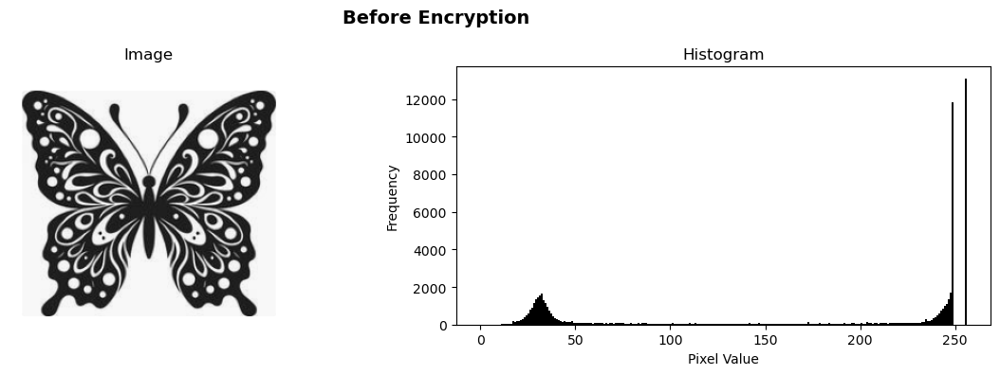

Entropy of Original Image: 5.4456 / 8.0
 Low entropy — image may not be sufficiently encrypted

     CORRELATION COEFFICIENT TABLE (Plain image)
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.939855       
Vertical       0.943197       
Diagonal       0.897751       


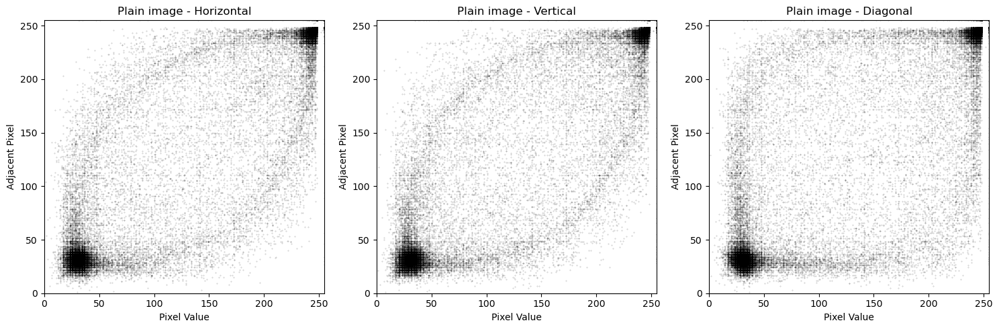

Processing: RSA


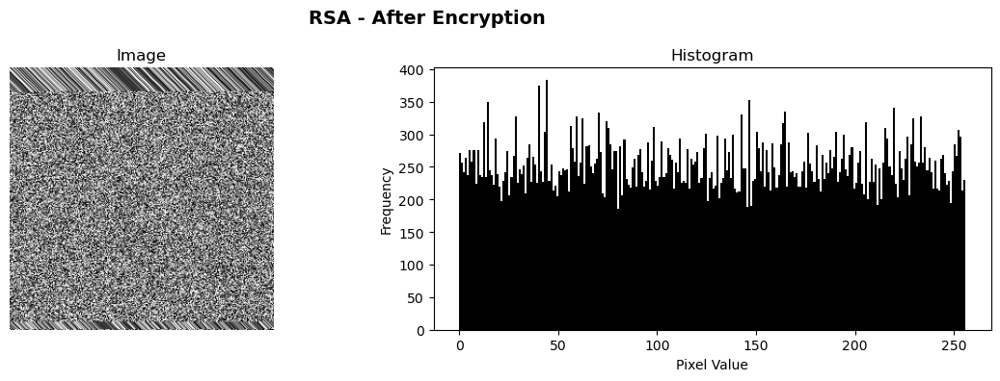

None

Entropy of RSA - Encrypted Image: 7.9862 / 8.0
 High entropy — image appears highly random (good encryption)


7.986224702580143


     CORRELATION COEFFICIENT TABLE ({'RSA'})
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.012952       
Vertical       0.004876       
Diagonal       0.117849       


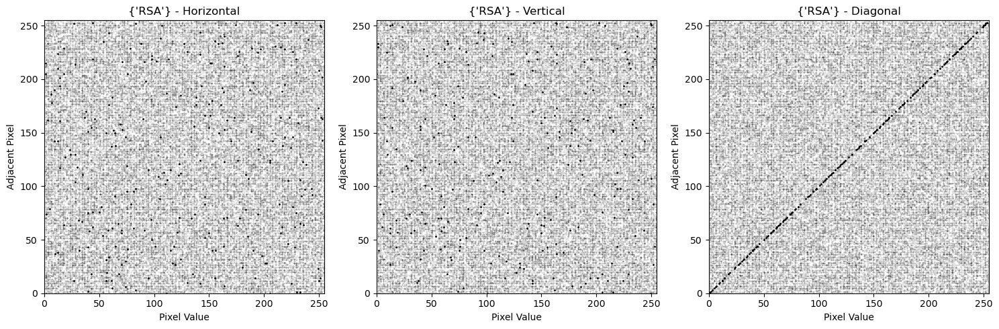

Processing: RSA + Padding


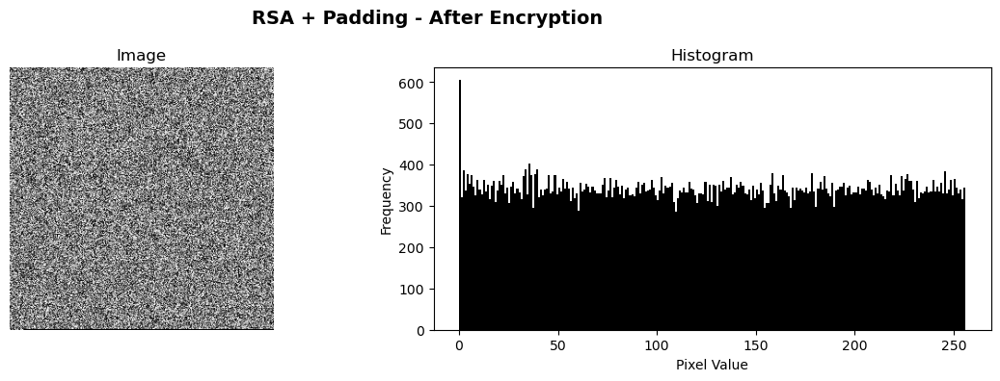

None

Entropy of RSA + Padding - Encrypted Image: 7.9964 / 8.0
 High entropy — image appears highly random (good encryption)


7.996367279512526


     CORRELATION COEFFICIENT TABLE ({'RSA + Padding'})
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.008361       
Vertical       0.000236       
Diagonal       0.001917       


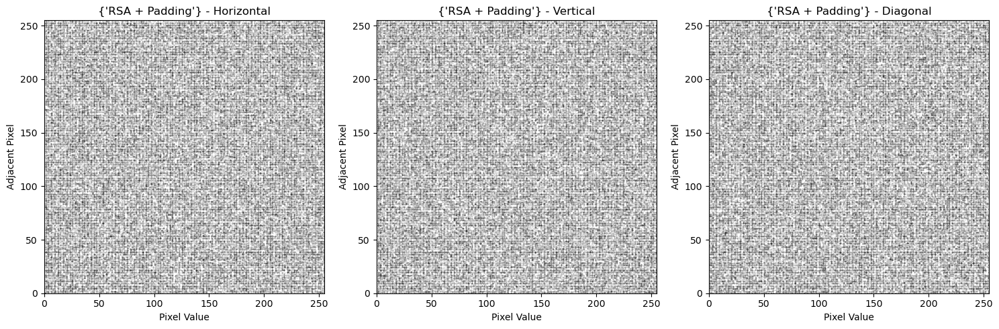

Processing: AES


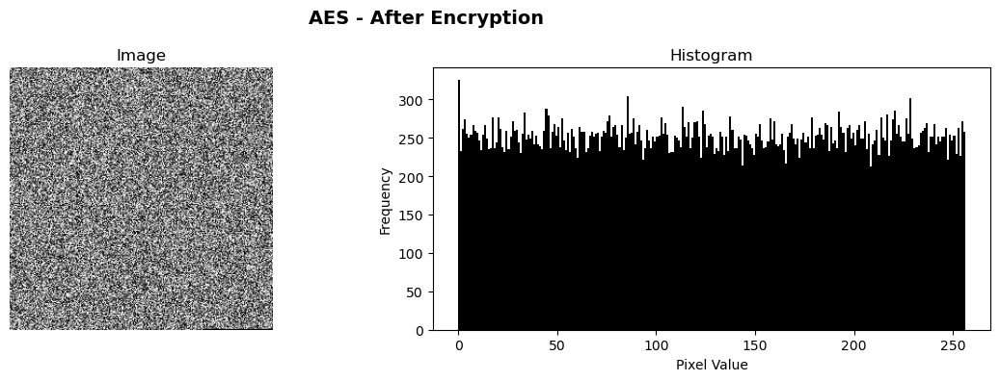

None

Entropy of AES - Encrypted Image: 7.9971 / 8.0
 High entropy — image appears highly random (good encryption)


7.997146104742091


     CORRELATION COEFFICIENT TABLE ({'AES'})
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.011774       
Vertical       -0.002963      
Diagonal       0.002506       


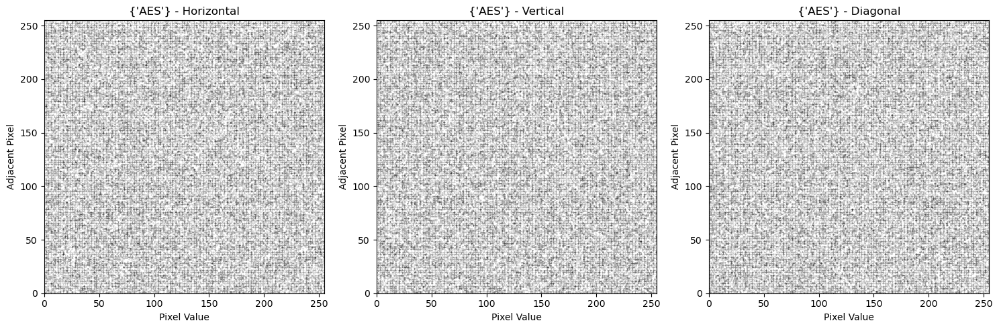

In [58]:
''' main ''' 
images = {
    "RSA": encrypted_img,
    "RSA + Padding": encrypted_img_padding,
    "AES": encrypted_img_AES}

plot_histogram(img, "Before Encryption")
compute_entropy(img,  "Original Image")
correlation_analysis(img, title="Plain image")
for name, image in images.items():

    print(f"Processing: {name}")

    display (plot_histogram(image, f"{name} - After Encryption"))

    display(compute_entropy(image, f"{name} - Encrypted Image"))
    correlation_analysis(image, title={name})


# Now , We Do The Same For The Colored Image 

0 = grayscale | 1 = colored :  1


 the original image before treating it with RSA 


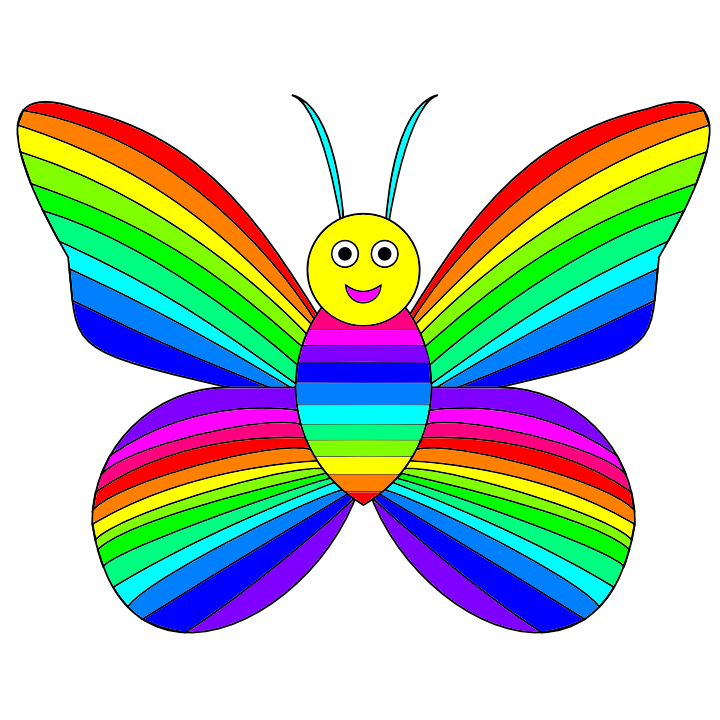

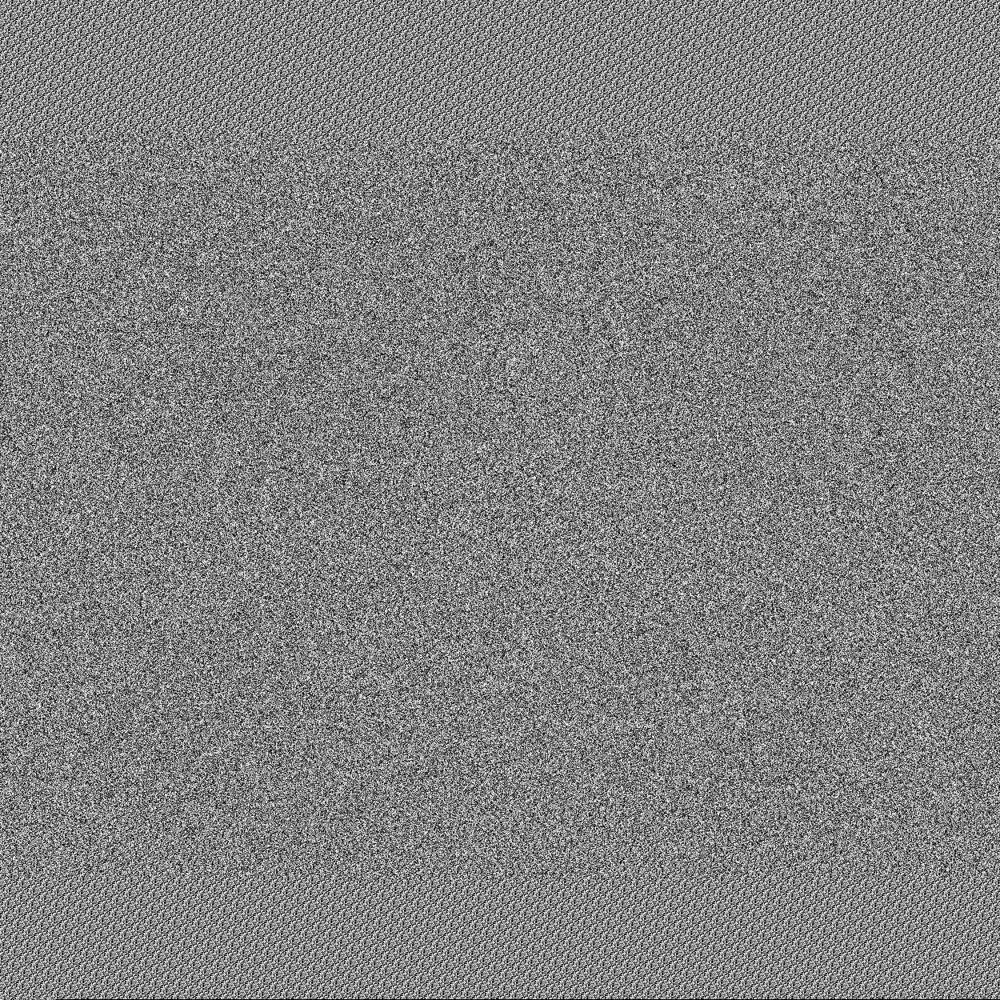

Decrypted image


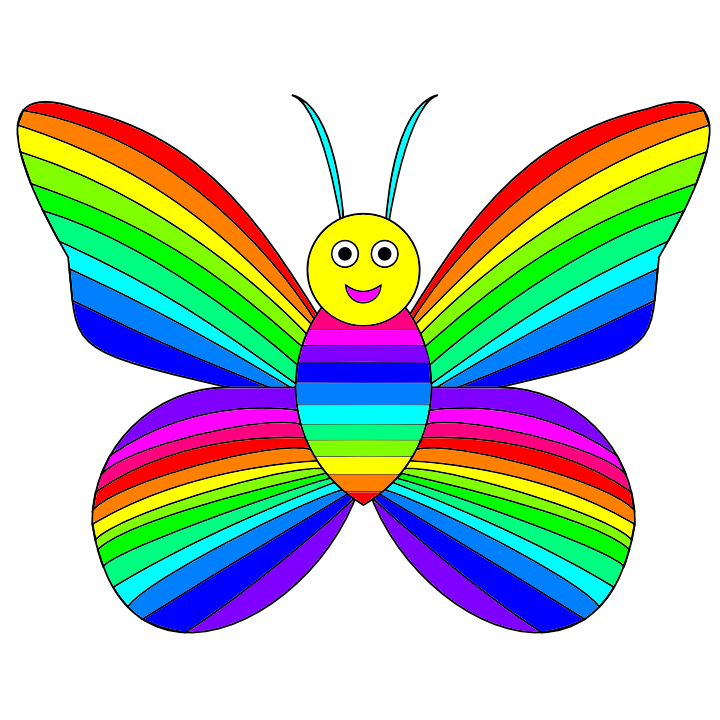

Execution Time is: 243.27814388275146 seconds


In [59]:
import time
start_time = time.time()
from IPython.display import display

# Open image
img = Image.open("Colored_butterfly.png")
if int(input("0 = grayscale | 1 = colored : ")) == 0:
    img = img.convert("L")    # we make the image uncolored
    
print (" the original image before treating it with RSA ")
display(img)

# finding the  height and width of the image
width , height = img.size 

# Convert image to numpy array
arr = np.array(img)

# Convert image to a 1D sequence of pixels
sequence = arr.flatten()
   
# Convert to Python list if needed
sequence_list = sequence.tolist()

# pixel list in binary 
binary_pixels = [format(i , '08b') for i in sequence_list]

# generate the RSA keys 
n , e , d , p ,q = RSA_keys ()

# finding the block size = number of pixel taken 
block_size = (math.floor(math.log2(n)))// 8

# constructing the blocks in binary 
blocks = [
    ''.join(binary_pixels[i:i + block_size])             # concatenation of pixels bits 
    for i in range(0, len(binary_pixels), block_size)
]

# converting each block number to decimal to encrypt it 
blocks_int= [ right_to_left_binary (i) for i in blocks ]
last_block_size = len(str(blocks[len(blocks)-1]))    

# calling the RSA function to encrypt the pixels blocks
encrypted = RSA_encryption (blocks_int , e , n)

''' CREATE A VISUAL ENCRYPTED IMAGE '''
encrypted_img = encrypted_image(encrypted, 'R' )
display (encrypted_img)

# calling the RSA function to decrypt the ciphertexts 
decrypted = RSA_decryption (encrypted, p , q , n ,d )

''' recover the image pixel sequence after decryption '''

# convert the decrypted list to binary to be able to divide each block to pixels bit
binary_decrypted=[]
for i in range (0,len(decrypted)-1):
    binary_decrypted.append(decimal_to_binary( decrypted[i] , block_size*8 ))
binary_decrypted.append(decimal_to_binary ( decrypted[len(decrypted)-1] , last_block_size))

# going back to binary pixel each pixel alone  
all_bits = ''.join(binary_decrypted)
recovered_pixel_bit = [
       all_bits[i:i+8]
       for i in range(0, len(all_bits), 8)
       ]

# convert the pixel bits to decimal 
recovered_pixel = [right_to_left_binary(b) for b in recovered_pixel_bit]

''' display the image each mode alone '''

# for colored image 
if img.mode == 'RGB':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 3))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGB')
    
if img.mode == 'RGBA':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 4))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGBA')


# for uncolored image 
if img.mode == 'L':
    arr = np.array(recovered_pixel)
    arr = arr.reshape((height, width))
    img_rec = Image.fromarray(arr.astype('uint8'), mode='L')

print("Decrypted image")
display(img_rec)
end_time = time.time()
print("Execution Time is:", end_time - start_time, "seconds")



0 = grayscale | 1 = colored :  1


 the original image before treating it with RSA+Padding is: 


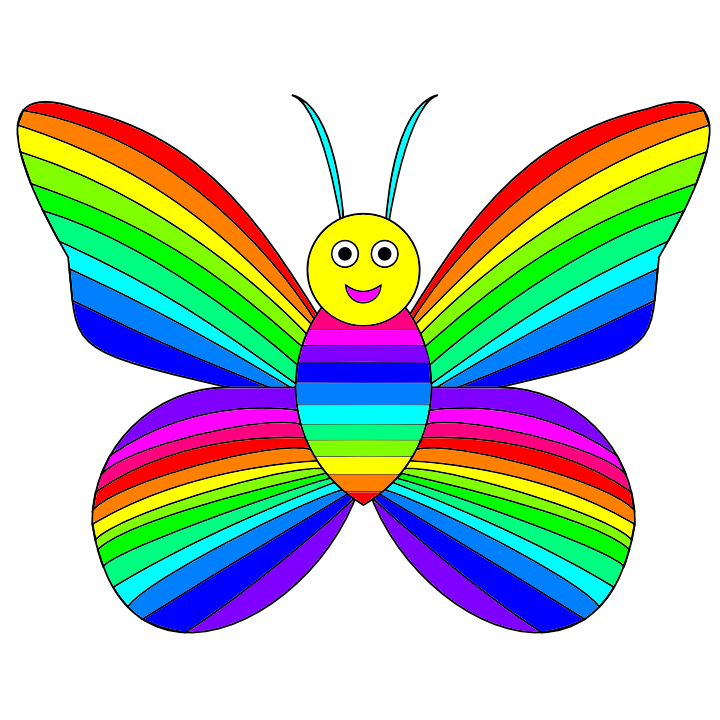

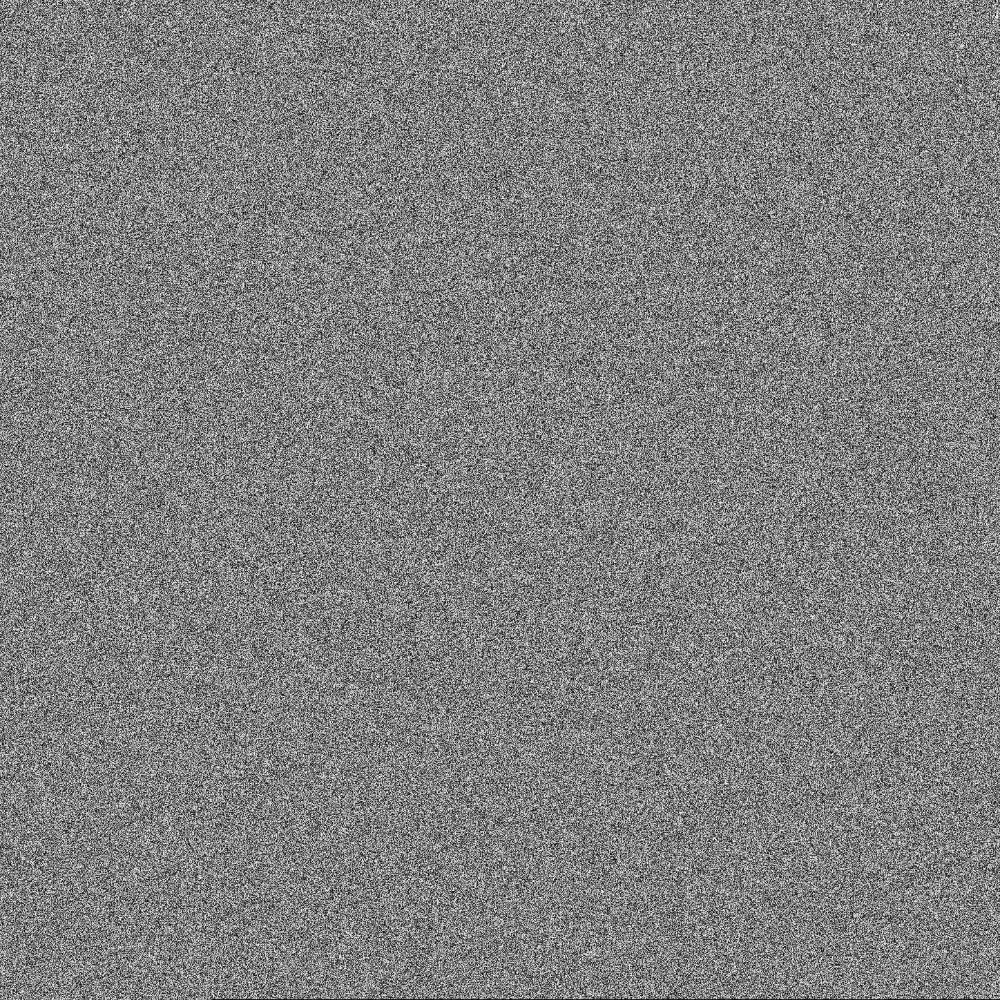

decrypted image


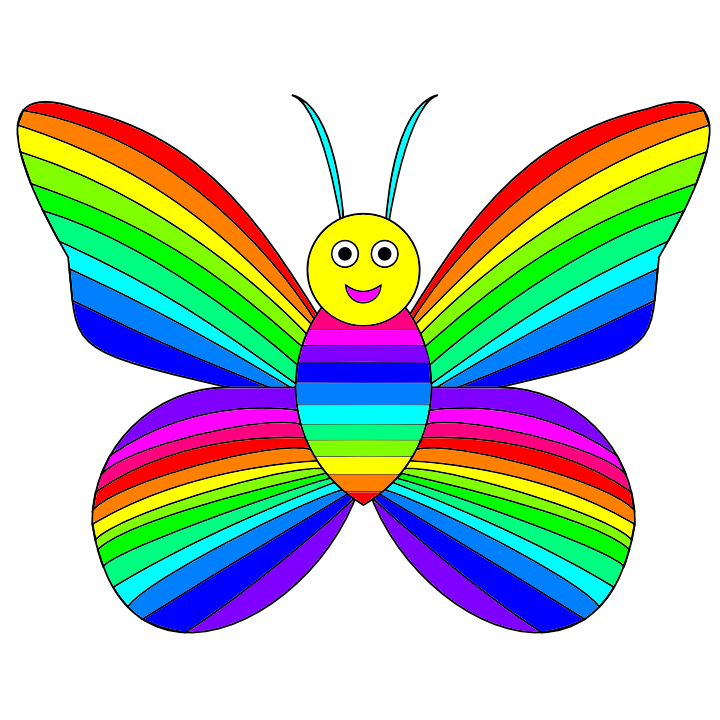

Execution Time: 316.9228973388672 seconds


In [60]:
start_time = time.time()
# Open image
img = Image.open("Colored_butterfly.png")

if int(input("0 = grayscale | 1 = colored : ")) == 0:
    img = img.convert("L")    # we make the image uncolored
    
print (" the original image before treating it with RSA+Padding is: ")
display(img)

# finding the  height and width of the image
width , height = img.size 

# Convert image to numpy array
arr = np.array(img)

# Convert image to a 1D sequence of pixels
sequence = arr.flatten()
   
# Convert to Python list if needed
sequence_list = sequence.tolist()

# pixel list in binary 
binary_pixels = [format(i , '08b') for i in sequence_list]

n_1 , e_1 , d_1 , p_1 ,q_1 = RSA_keys ()

# finding the block size = number of pixel taken 
hLen = 32
k = (n.bit_length() + 7) // 8

# we calculate the block size as before then we substruct the length of what we will add it in the OEAP padding
# hLen for seed , hlen for hashing the label ,1 byte for separator and 1 for the leading 0x00
block_size_1 = ( k - 2*hLen - 2)

# constructing the blocks in binary 
blocks = [
    ''.join(binary_pixels[i:i + block_size_1])             # concatenation of pixels bits 
    for i in range(0, len(binary_pixels), block_size_1)
]

# converting each block number to decimal to encrypt it 
blocks_int= [ right_to_left_binary (i) for i in blocks ]
last_block_size_1 = len(str(blocks[len(blocks)-1]))

#convert the block of integers to a block of bytes-OEAP works with bytes 
blocks_bytes = [
    block.to_bytes((block.bit_length() + 7)//8, 'big')
    for block in blocks_int
]
blocks_int_oeap = [oaep_encode(block, k, label=b'') for block in blocks_bytes]

# calling the RSA function to encrypt the pixels blocks 
#we must convert the blocks from bytes to integers 
encrypted_1 = [
    power(int.from_bytes(block, 'big'), e_1, n_1)
    for block in blocks_int_oeap
]

''' CREATE A VISUAL ENCRYPTED IMAGE '''
encrypted_img_padding = encrypted_image(encrypted_1 , 'R')
display(encrypted_img_padding)

# calling the RSA function to decrypt the ciphertexts 
decrypted_1 = RSA_decryption (encrypted_1, p_1 , q_1 , n_1 , d_1 )

#convert the decrypted block into bytes for use it in oaep_decode
decrypted_bytes = [
    block.to_bytes(k, 'big')
    for block in decrypted_1
]
decrypted_decoded =[ oaep_decode(decrypted_block, k, label=b'') for decrypted_block in decrypted_bytes]
decrypted_decoded_int= [
    int.from_bytes(block, 'big')
    for block in decrypted_decoded
]

''' recover the image pixel sequence after decryption '''

# convert the decrypted list to binary to be able to divide each block to pixels bit
binary_decrypted=[]
for i in range (0,len(decrypted_decoded)-1):
    binary_decrypted.append(decimal_to_binary(
    int.from_bytes(decrypted_decoded[i], 'big'),
    block_size_1 * 8
))
binary_decrypted.append(
    decimal_to_binary(
        int.from_bytes(decrypted_decoded[-1], 'big'),
        last_block_size_1
    )
)

# going back to binary pixel each pixel alone  
all_bits = ''.join(binary_decrypted)
recovered_pixel_bit = [
       all_bits[i:i+8]
       for i in range(0, len(all_bits), 8)
       ]

# convert the pixel bits to decimal 
recovered_pixel = [right_to_left_binary(b) for b in recovered_pixel_bit]

''' display the image each mode alone '''

# for colored image 
if img.mode == 'RGB':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 3))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGB')
    
if img.mode == 'RGBA':
           arr = np.array(recovered_pixel)
           arr2= arr.reshape((height, width, 4))
           img_rec= Image.fromarray(arr2.astype('uint8'), mode='RGBA')


# for uncolored image 
if img.mode == 'L':
    arr = np.array(recovered_pixel)
    arr = arr.reshape((height, width))
    img_rec = Image.fromarray(arr.astype('uint8'), mode='L')

print("decrypted image")
display(img_rec)
end_time = time.time()
print("Execution Time:", end_time - start_time, "seconds")


0 = grayscale | 1 = colored :  1


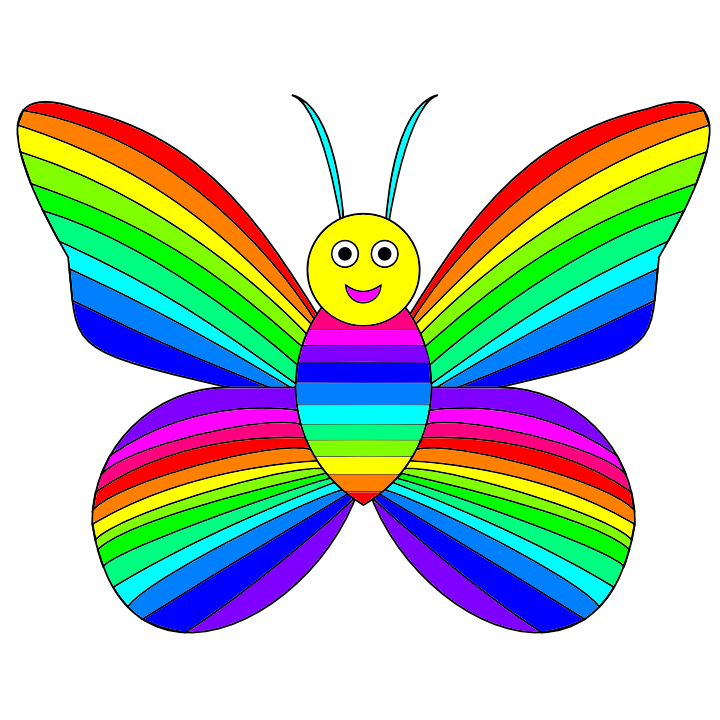

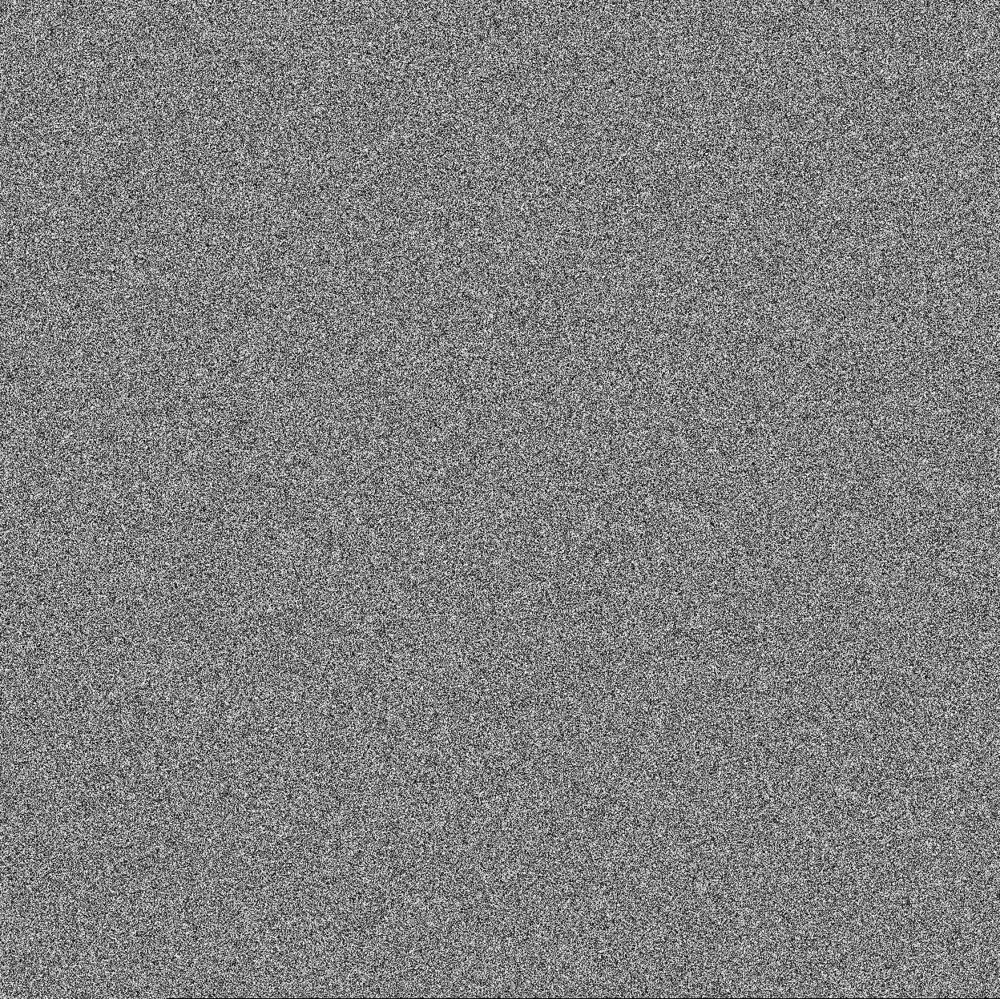

Decrypted Image


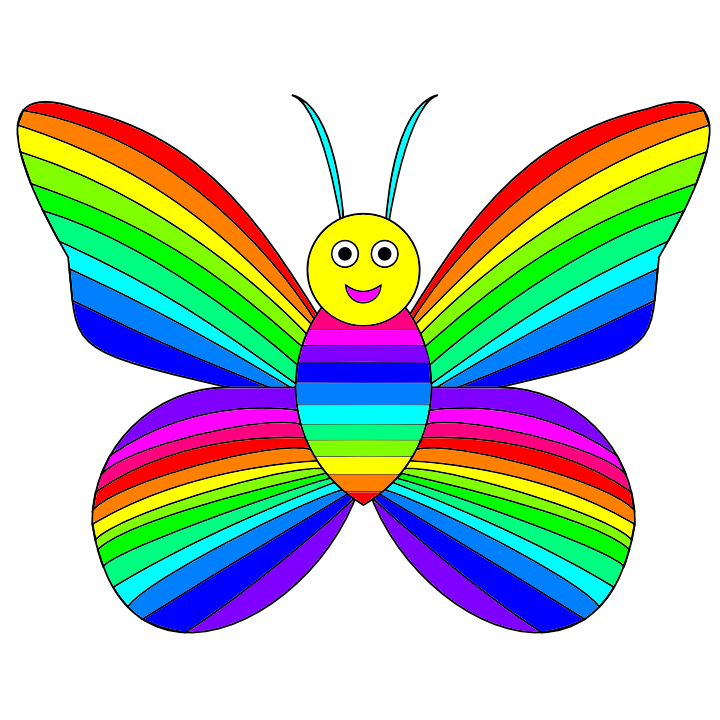

Execution Time: 8.742405891418457 seconds


In [61]:
import time, os, numpy as np
from PIL import Image
from IPython.display import display
from Crypto.Cipher import AES
from Crypto.Util.Padding import pad, unpad

start_time = time.time()

# open image
img = Image.open("Colored_butterfly.png")

if int(input("0 = grayscale | 1 = colored : ")) == 0:
    img = img.convert("L")    # we make the image uncolored
display(img)

width, height = img.size
arr = np.array(img)

# image to bytes
image_bytes = arr.tobytes()

# AES encryption
aes_key = os.urandom(32)

cipher = AES.new(aes_key, AES.MODE_CBC)

ciphertext = cipher.encrypt(pad(image_bytes , AES.block_size))

iv = cipher.iv

''' display the encrypted image '''
encrypted_img_AES = encrypted_image(ciphertext , 'A')
display(encrypted_img_AES)

# RSA KEY EXCHANGE
# (using your RSA functions)
n_2, e_2, d_2, p_2, q_2 = RSA_keys()

# convert the AES key to integer
aes_int = int.from_bytes(aes_key, 'big')

# RSA encryption
encrypted_key = power(aes_int, e_2, n_2)

# RSA decryption
decrypted_key_int = power(encrypted_key, d_2, n_2)

# integer to bytes
recovered_key = decrypted_key_int.to_bytes(32, 'big')

# AES DECRYPTION
cipher_dec = AES.new(recovered_key , AES.MODE_CBC , iv=iv)

decrypted_bytes = unpad(cipher_dec.decrypt(ciphertext), AES.block_size)


# Rebuild image
recovered_arr = np.frombuffer(decrypted_bytes , dtype=np.uint8).reshape(arr.shape)
img_rec = Image.fromarray(recovered_arr.astype(np.uint8) , mode=img.mode)

print("Decrypted Image")
display(img_rec)

# execution time 
end_time = time.time()
print("Execution Time:", end_time - start_time, "seconds")


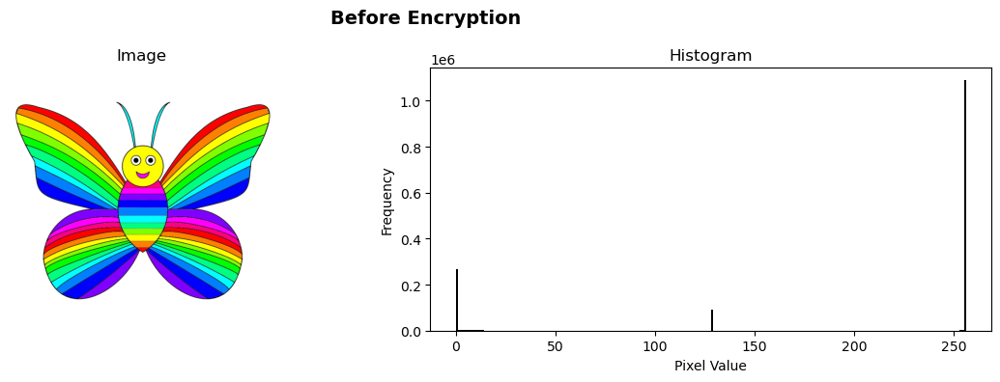

Entropy of Original Image: 1.8202 / 8.0
 Low entropy — image may not be sufficiently encrypted

     CORRELATION COEFFICIENT TABLE (Plain image)
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.957811       
Vertical       0.929806       
Diagonal       0.916154       


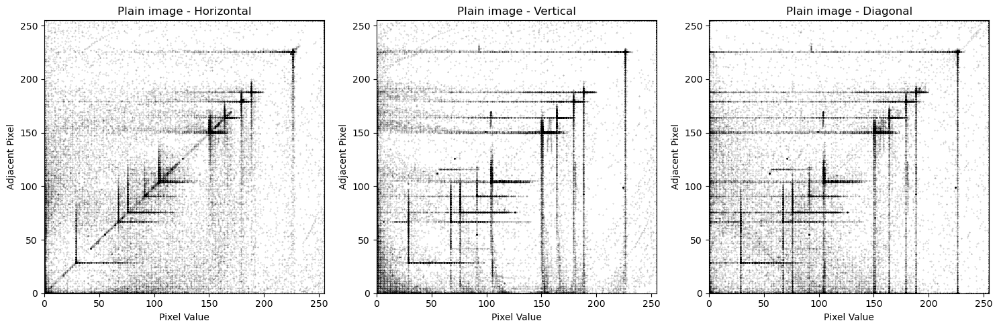

Processing: RSA


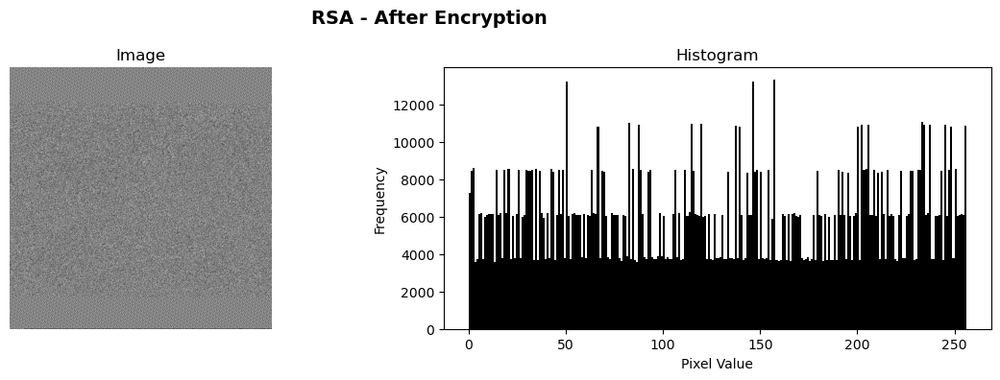

None

Entropy of RSA - Encrypted Image: 7.9049 / 8.0
 High entropy — image appears highly random (good encryption)


7.904851346973468


     CORRELATION COEFFICIENT TABLE ({'RSA'})
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.035493       
Vertical       0.005953       
Diagonal       -0.038807      


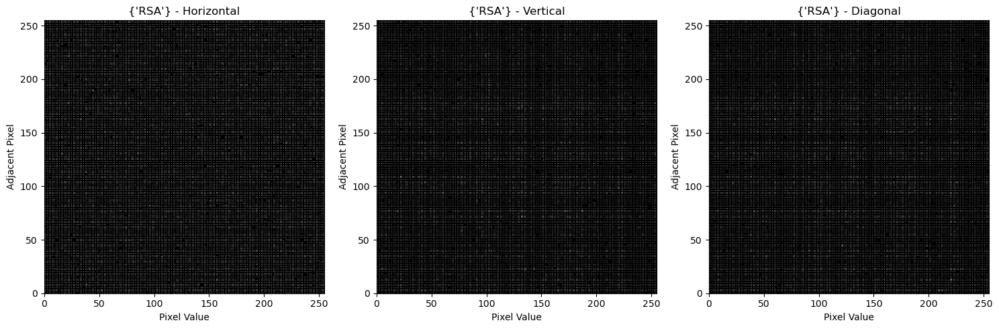

Processing: RSA + Padding


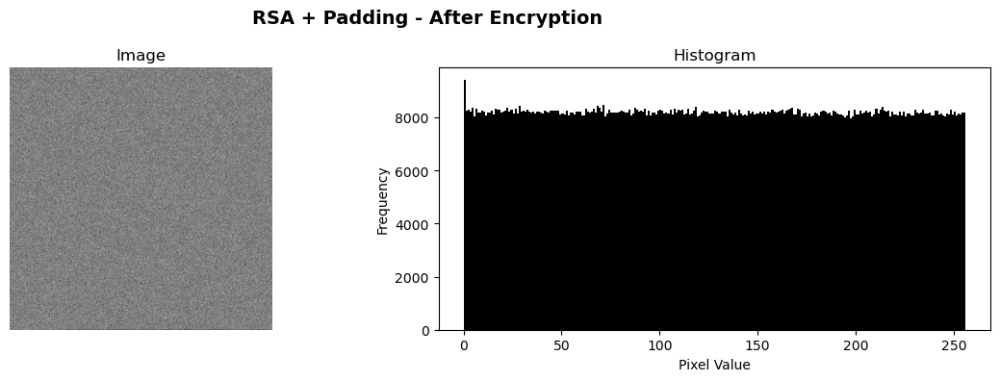

None

Entropy of RSA + Padding - Encrypted Image: 7.9999 / 8.0
 High entropy — image appears highly random (good encryption)


7.999859941106025


     CORRELATION COEFFICIENT TABLE ({'RSA + Padding'})
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.001190       
Vertical       0.001173       
Diagonal       0.000550       


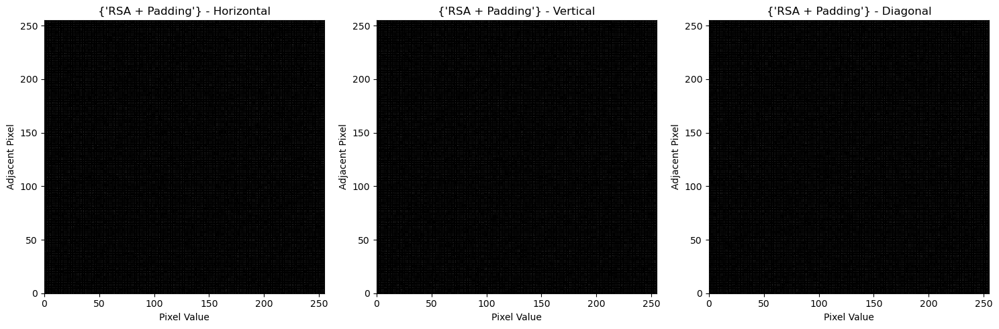

Processing: AES


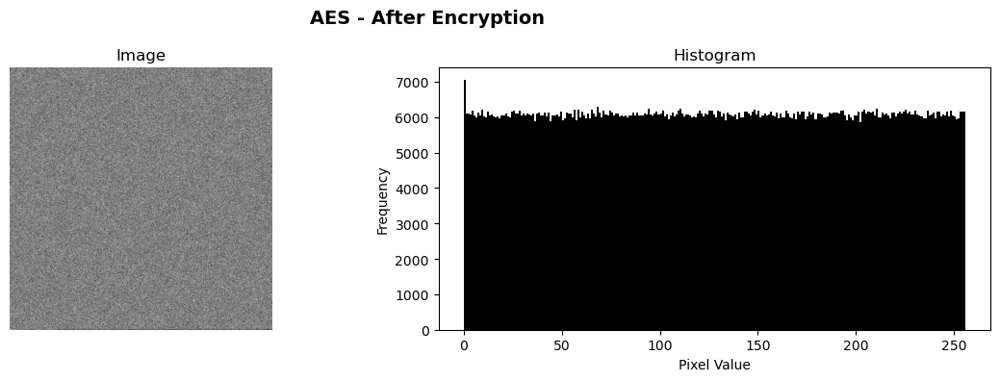

None

Entropy of AES - Encrypted Image: 7.9998 / 8.0
 High entropy — image appears highly random (good encryption)


7.999821813922557


     CORRELATION COEFFICIENT TABLE ({'AES'})
Direction      Correlation    
------------------------------------------------------------
Horizontal     0.001173       
Vertical       0.000306       
Diagonal       0.000498       


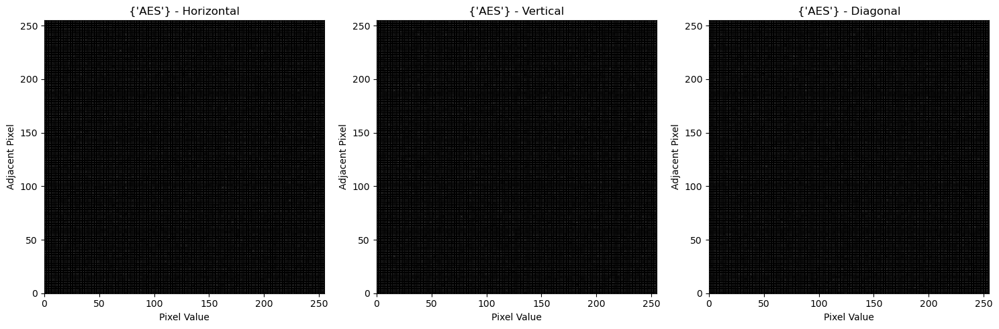

In [62]:
''' main ''' 
images = {
    "RSA": encrypted_img,
    "RSA + Padding": encrypted_img_padding,
    "AES": encrypted_img_AES}

plot_histogram(img, "Before Encryption")
compute_entropy(img,  "Original Image")
correlation_analysis(img, title="Plain image")
for name, image in images.items():

    print(f"Processing: {name}")

    display (plot_histogram(image, f"{name} - After Encryption"))

    display(compute_entropy(image, f"{name} - Encrypted Image"))
    correlation_analysis(image, title={name})
